# Penerapan Machine Learning untuk Klasifikasi Status Kelulusan Mahasiswa
**Metode: Decision Tree Classifier**

Nama: Disa Nastha Gesiya
NIM: 2404010011
Mata Kuliah : Data Mining

## 1. Permasalahan
Perguruan tinggi perlu mengetahui mahasiswa yang berpotensi menyelesaikan studi dengan baik dan mahasiswa yang berisiko belum menyelesaikan studi dalam waktu yang diharapkan. Informasi tersebut dapat membantu pihak kampus mempertimbangkan dukungan akademik, misalnya konsultasi dosen wali atau pendampingan belajar.

Pada tugas ini, Machine Learning digunakan untuk mengklasifikasikan status mahasiswa berdasarkan data akademik dan informasi saat pendaftaran.

**Penting tentang label dataset:** dataset publik yang dipakai menyediakan tiga status: *Dropout*, *Enrolled* (masih terdaftar), dan *Graduate*. Dataset ini tidak menyediakan label khusus “lulus tepat waktu” dan “lulus terlambat”. Agar tetap memakai dataset nyata yang mudah diakses, tugas ini mengubahnya menjadi dua kelas proxy:
- **Lulus**: status `Graduate`.
- **Belum lulus / berisiko terlambat**: status `Enrolled` atau `Dropout`.

Jadi, kelas kedua bukan berarti semua mahasiswa pasti terlambat; kelas ini menggabungkan mahasiswa yang masih terdaftar dan yang berhenti kuliah. Batasan ini harus disebutkan dalam pembahasan. Untuk benar-benar memprediksi lulus tepat waktu vs terlambat, diperlukan dataset yang memiliki label waktu kelulusan aktual.

## 2. Dataset
Dataset **Predict Students' Dropout and Academic Success** dari UCI Machine Learning Repository. Dataset berisi 4.424 catatan mahasiswa dan 36 fitur, termasuk informasi saat pendaftaran serta kinerja akademik semester pertama dan kedua. Target aslinya memiliki tiga kategori: `Dropout`, `Enrolled`, dan `Graduate`.

Sumber: https://archive.ics.uci.edu/dataset/697/predict+students+dropout+and+academic+success

## 3. Metode klasifikasi
Algoritma yang digunakan adalah **Decision Tree Classifier** (pohon keputusan). Model membagi data berdasarkan kondisi fitur, lalu menghasilkan prediksi kelas. Metode ini dipilih karena sederhana dan relatif mudah dijelaskan melalui aturan keputusan.

## 4. Tahapan penerapan
1. Mengambil dataset publik dari UCI.
2. Menggabungkan label asli menjadi dua kelas proxy sesuai penjelasan di atas.
3. Memisahkan fitur dan target, lalu membagi data menjadi 80% data latih dan 20% data uji.
4. Menangani kolom numerik dan kategorikal menggunakan preprocessing otomatis.
5. Melatih Decision Tree.
6. Mengukur accuracy, precision, recall, F1-score, dan confusion matrix.
7. Menyimpulkan hasil beserta keterbatasannya.


In [18]:
# 1. Memasang dan memuat pustaka
!pip -q install ucimlrepo

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay
)

print("Pustaka siap digunakan.")

Pustaka siap digunakan.
Pustaka siap digunakan.


In [19]:
# 2. Mengambil dataset dari UCI Machine Learning Repository
dataset = fetch_ucirepo(id=697)

X = dataset.data.features.copy()
y_asli = dataset.data.targets.iloc[:, 0].astype(str)

print("Ukuran fitur:", X.shape)
print("\nDistribusi target asli:")
display(y_asli.value_counts().to_frame("Jumlah mahasiswa"))
display(X.head())

Ukuran fitur: (4424, 36)

Distribusi target asli:


,Jumlah mahasiswa
Target,
Graduate,2209
Dropout,1421
Enrolled,794


,Marital Status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0,0.000000,0,10.8,1.4,1.74
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,0,6,6,6,13.666667,0,13.9,-0.3,0.79
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,0,6,0,0,0.000000,0,10.8,1.4,1.74
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,0,6,10,5,12.400000,0,9.4,-0.8,-3.12
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,0,6,6,6,13.000000,0,13.9,-0.3,0.79


Distribusi target untuk klasifikasi:


,Jumlah mahasiswa
Target,
Belum lulus / berisiko terlambat,2215
Lulus,2209


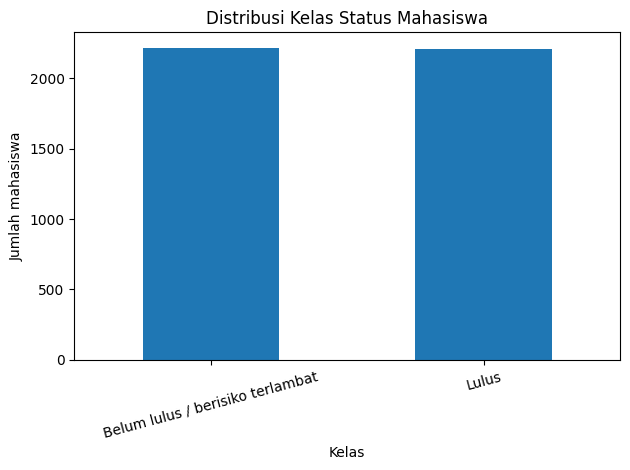

In [20]:
# 3. Membentuk target dua kelas (proxy)
# Graduate = Lulus
# Enrolled dan Dropout = Belum lulus / berisiko terlambat
y = y_asli.apply(
    lambda status: "Lulus" if status.strip().lower() == "graduate"
    else "Belum lulus / berisiko terlambat"
)

print("Distribusi target untuk klasifikasi:")
display(y.value_counts().to_frame("Jumlah mahasiswa"))

y.value_counts().plot(kind="bar", rot=15)
plt.title("Distribusi Kelas Status Mahasiswa")
plt.xlabel("Kelas")
plt.ylabel("Jumlah mahasiswa")
plt.tight_layout()
plt.show()

In [21]:
# 4. Membagi data latih dan data uji
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Mengenali kolom numerik dan kategorikal
kolom_numerik = X_train.select_dtypes(include=["number"]).columns.tolist()
kolom_kategorikal = X_train.select_dtypes(exclude=["number"]).columns.tolist()

print("Jumlah data latih:", len(X_train))
print("Jumlah data uji:", len(X_test))
print("Fitur numerik:", len(kolom_numerik))
print("Fitur kategorikal:", len(kolom_kategorikal))

Jumlah data latih: 3539
Jumlah data uji: 885
Fitur numerik: 36
Fitur kategorikal: 0


In [22]:
# 5. Preprocessing dan pelatihan Decision Tree
# Nilai kosong diisi median/modus; fitur kategorikal diubah menjadi angka.
proses_numerik = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

proses_kategorikal = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("numerik", proses_numerik, kolom_numerik),
    ("kategorikal", proses_kategorikal, kolom_kategorikal)
])

model = Pipeline(steps=[
    ("preprocessing", preprocessor),
    ("classifier", DecisionTreeClassifier(
        max_depth=5,
        random_state=42,
        class_weight="balanced"
    ))
])

model.fit(X_train, y_train)
print("Model selesai dilatih.")

Model selesai dilatih.


In [23]:
# 6. Evaluasi pada data uji
y_pred = model.predict(X_test)

akurasi = accuracy_score(y_test, y_pred)
print(f"Akurasi: {akurasi:.3f} ({akurasi*100:.2f}%)")
print("\nLaporan klasifikasi:")
print(classification_report(y_test, y_pred, digits=3, zero_division=0))

Akurasi: 0.795 (79.55%)

Laporan klasifikasi:
                                  precision    recall  f1-score   support

Belum lulus / berisiko terlambat      0.836     0.736     0.783       443
                           Lulus      0.764     0.855     0.807       442

                        accuracy                          0.795       885
                       macro avg      0.800     0.796     0.795       885
                    weighted avg      0.800     0.795     0.795       885



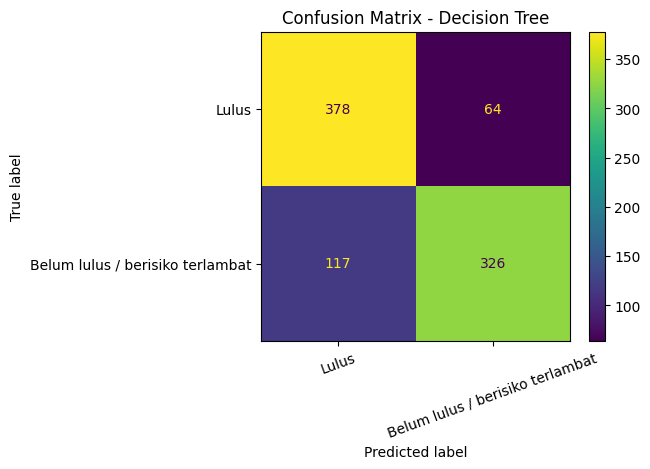

Confusion matrix (baris = status sebenarnya, kolom = prediksi):
                                  Lulus  Belum lulus / berisiko terlambat
Lulus                               378                                64
Belum lulus / berisiko terlambat    117                               326


In [24]:
# 7. Confusion matrix
label_urut = ["Lulus", "Belum lulus / berisiko terlambat"]
cm = confusion_matrix(y_test, y_pred, labels=label_urut)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=label_urut)
disp.plot(values_format="d", xticks_rotation=20)
plt.title("Confusion Matrix - Decision Tree")
plt.tight_layout()
plt.show()

print("Confusion matrix (baris = status sebenarnya, kolom = prediksi):")
print(pd.DataFrame(cm, index=label_urut, columns=label_urut))

In [25]:
# 8. Contoh hasil prediksi untuk beberapa mahasiswa pada data uji
contoh_hasil = X_test.head(5).copy()
contoh_hasil["Status sebenarnya"] = y_test.loc[contoh_hasil.index]
contoh_hasil["Prediksi model"] = model.predict(X_test.loc[contoh_hasil.index])
display(contoh_hasil[["Status sebenarnya", "Prediksi model"]])

,Status sebenarnya,Prediksi model
3412,Belum lulus / berisiko terlambat,Belum lulus / berisiko terlambat
2664,Lulus,Lulus
3640,Lulus,Lulus
3238,Lulus,Lulus
3998,Belum lulus / berisiko terlambat,Belum lulus / berisiko terlambat


## 5. Hasil dan pembahasan
Jalankan seluruh sel kode untuk memperoleh angka evaluasi dari data uji. Angka akurasi dan laporan klasifikasi akan tampil otomatis, sehingga hasil yang ditulis dalam laporan sesuai dengan hasil eksekusi notebook.

- **Accuracy**: persentase seluruh prediksi yang benar.
- **Precision**: seberapa tepat prediksi pada suatu kelas.
- **Recall**: seberapa banyak anggota kelas sebenarnya yang berhasil dikenali.
- **F1-score**: ukuran gabungan precision dan recall.
- **Confusion matrix**: menunjukkan jumlah prediksi benar dan salah untuk setiap kelas.

Akurasi yang tinggi tidak selalu berarti model sudah baik untuk semua kelas. Bandingkan precision dan recall, terutama karena jumlah mahasiswa pada tiap status bisa berbeda.

## 6. Manfaat
1. Mencontohkan penerapan klasifikasi Machine Learning pada data pendidikan tinggi.
2. Membantu memahami bagaimana data mahasiswa digunakan untuk mempelajari pola status akademik.
3. Menjadi gambaran awal sistem pendukung keputusan untuk menentukan kebutuhan pendampingan mahasiswa.

## 7. Keterbatasan
Target pada dataset asli bukan status lulus tepat waktu atau terlambat. Kategori “Belum lulus / berisiko terlambat” merupakan penggabungan status `Enrolled` dan `Dropout`, sehingga tidak boleh ditafsirkan sebagai prediksi keterlambatan kelulusan yang pasti. Selain itu, dataset berasal dari satu institusi pendidikan dan tidak otomatis mewakili semua perguruan tinggi. Model ini hanya untuk pembelajaran, bukan untuk mengambil keputusan akademik secara otomatis.

## 8. Kesimpulan
Decision Tree digunakan untuk mengklasifikasikan status mahasiswa menjadi dua kelas berdasarkan fitur akademik dan informasi pendaftaran. Kinerja model dievaluasi menggunakan accuracy, precision, recall, F1-score, dan confusion matrix. Hasil numerik akhir harus mengacu pada keluaran notebook setelah seluruh kode dijalankan. Untuk penelitian yang benar-benar memprediksi kelulusan tepat waktu atau terlambat, diperlukan dataset yang mencantumkan waktu kelulusan dan batas waktu kelulusan resmi.

## Daftar referensi
1. Realinho, V., Vieira Martins, M., Machado, J., & Baptista, L. (2021). *Predict Students' Dropout and Academic Success* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5MC89
2. UCI Machine Learning Repository. *Predict Students' Dropout and Academic Success*. https://archive.ics.uci.edu/dataset/697/predict+students+dropout+and+academic+success
3. Scikit-learn developers. *DecisionTreeClassifier documentation*. https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html
4. Scikit-learn developers. *Model evaluation: quantifying the quality of predictions*. https://scikit-learn.org/stable/modules/model_evaluation.html
